In [1]:
# ==========================================
# Cell 1: Imports and Test Directory Setup
# ==========================================
import os
import glob
import pickle
import numpy as np
from astropy.io import fits
from astropy.table import vstack
import matplotlib.pyplot as plt
from tqdm import tqdm
from lsst.daf.butler import Butler
from slsim.LsstSciencePipeline import lsst_science_pipeline

from utils import (
    extract_non_lens_properties, robust_batch_lens_injection, patch_is_crowded,
    plot_injected_montage, plot_noise_std_histograms,
)

import warnings
warnings.filterwarnings("ignore")

%load_ext autoreload
%autoreload 2

img_dir = "../data_injected_test/non-lenses/images/"
os.makedirs(img_dir, exist_ok=True)


In [2]:
# ==========================================
# Cell 2: Load a Small Test Batch of Non-Lenses
# ==========================================
non_lens_categories = ["gal_gal_agn", "qso_gal", "qso_qso", "qso_star", "star_star"]
has_light = ["gal_gal_agn", "qso_gal", "cusp_mimic"]
num_test_per_category = 60  # ~300 total spread evenly across the 5 categories

non_lenses_test = []
category_counts_test = {}
for cat in non_lens_categories:
    files = sorted(glob.glob(f"../saved_objects/nonlenses_{cat}_*.pkl"))
    cat_objects = []
    for file in files:
        with open(file, "rb") as f:
            cat_objects.extend(pickle.load(f))
        if len(cat_objects) >= num_test_per_category:
            break
    cat_objects = cat_objects[:num_test_per_category]
    non_lenses_test.extend(cat_objects)
    category_counts_test[cat] = len(cat_objects)
    print(f"Loaded {len(cat_objects)} {cat} objects for the test run.")

print(f"Total non-lenses loaded for test: {len(non_lenses_test)}")


Loaded 60 gal_gal_agn objects for the test run.
Loaded 60 qso_gal objects for the test run.
Loaded 60 qso_qso objects for the test run.
Loaded 60 qso_star objects for the test run.
Loaded 60 star_star objects for the test run.
Total non-lenses loaded for test: 300


In [3]:
# ==========================================
# Cell 3: Extract Properties for the Test Batch
# ==========================================
all_tables = []
cat_track_index = 0
for cat in non_lens_categories:
    cat_objects = non_lenses_test[cat_track_index: cat_track_index + category_counts_test[cat]]
    has_central = cat in has_light
    cat_table = extract_non_lens_properties(
        cat_objects, has_central_object=has_central, starting_index=cat_track_index
    )
    all_tables.append(cat_table)
    cat_track_index += category_counts_test[cat]

table_test = vstack(all_tables)


In [4]:
# ==========================================
# Cell 4: Initialize Butler and Injection Parameters
# ==========================================
print("Initializing Butler...")
butler = Butler("dp02", collections="2.2i/runs/DP0.2")

band_list = ['g', 'r', 'i', 'z', 'y']
num_pix = 41
pixel_scale = 0.2
transform_matrix = np.array([[pixel_scale, 0], [0, pixel_scale]])
lenses_per_patch = 300

Initializing Butler...


In [5]:
# ==========================================
# Cell 5: Inject the Test Batch
# ==========================================
pending_indices = list(range(len(non_lenses_test)))
successful_indices = []
attempt_counts = {}
max_patch_attempts = 15  # bounded so a bad patch can't hang the test run

with tqdm(total=len(non_lenses_test)) as pbar:
    while pending_indices:
        batch_indices = pending_indices[:lenses_per_patch]
        remaining = pending_indices[lenses_per_patch:]
        current_batch = [non_lenses_test[i] for i in batch_indices]

        ra = np.random.uniform(55.0, 70.0)
        dec = np.random.uniform(-43.0, -30.0)

        try:
            coadd_list, coadd_nImage_list, _, variance_map_list = lsst_science_pipeline.get_dp0_images(
                butler=butler, ra=ra, dec=dec, band_list=band_list, coadd_injection=True
            )
            mag_zero_list = [2.5 * np.log10(c.getPhotoCalib().getInstFluxAtZeroMagnitude()) for c in coadd_list]
        except Exception:
            continue

        # Cheap pre-check: skip whole patches too crowded to be worth a full attempt
        if patch_is_crowded(coadd_list, variance_map_list, band_list, pixel_scale, num_pix):
            continue

        # lens_ids=batch_indices: match results back to the table by row index,
        # NOT by lens.generate_id() - that string is built from a couple of
        # rounded physical parameters and is not guaranteed unique across a
        # large/"balanced" sample, so it can silently collide between objects.
        batch_results, batch_failures = robust_batch_lens_injection(
            lens_batch=current_batch,
            lens_ids=batch_indices,
            num_pix=num_pix,
            coadd_list=coadd_list,
            coadd_nImage_list=coadd_nImage_list,
            mag_zero_list=mag_zero_list,
            variance_map_list=variance_map_list,
            transform_matrix=transform_matrix,
            band_list=band_list,
            coadd_year=1,
            max_retries=10,
            snr_threshold=5,
            verbose=False,
        )

        succeeded_indices = set()
        for sample in batch_results:
            idx = sample["row_id"]
            obj_id = table_test[idx]["Object ID"]
            table_test[idx]["RA"] = sample["cutout_center"][0]
            table_test[idx]["Dec"] = sample["cutout_center"][1]

            for band in band_list:
                fits_path = os.path.join(img_dir, f"{obj_id}_{band}.fits")
                fits.writeto(fits_path, sample["injected_images"][band], overwrite=True)

            successful_indices.append(idx)
            succeeded_indices.add(idx)
            pbar.update(1)

        still_pending = []
        for i in batch_indices:
            if i in succeeded_indices:
                continue
            reason = batch_failures.get(i, "unknown")
            obj_id_i = table_test[i]["Object ID"]
            if reason.startswith("exception"):
                tqdm.write(f"Dropping {obj_id_i} (index {i}) permanently - {reason}")
                continue
            attempt_counts[i] = attempt_counts.get(i, 0) + 1
            if attempt_counts[i] >= max_patch_attempts:
                tqdm.write(f"Warning: giving up on {obj_id_i} (index {i}) after {max_patch_attempts} patch attempts ({reason}).")
                continue
            still_pending.append(i)

        tqdm.write(f"Patch: {len(succeeded_indices)}/{len(batch_indices)} injected, {len(still_pending)} requeued.")
        pending_indices = remaining + still_pending

print(f"Injected {len(successful_indices)}/{len(non_lenses_test)} test non-lenses.")


100%|██████████| 300/300 [04:41<00:00,  1.07it/s]  


Patch: 300/300 injected, 0 requeued.
Injected 300/300 test non-lenses.


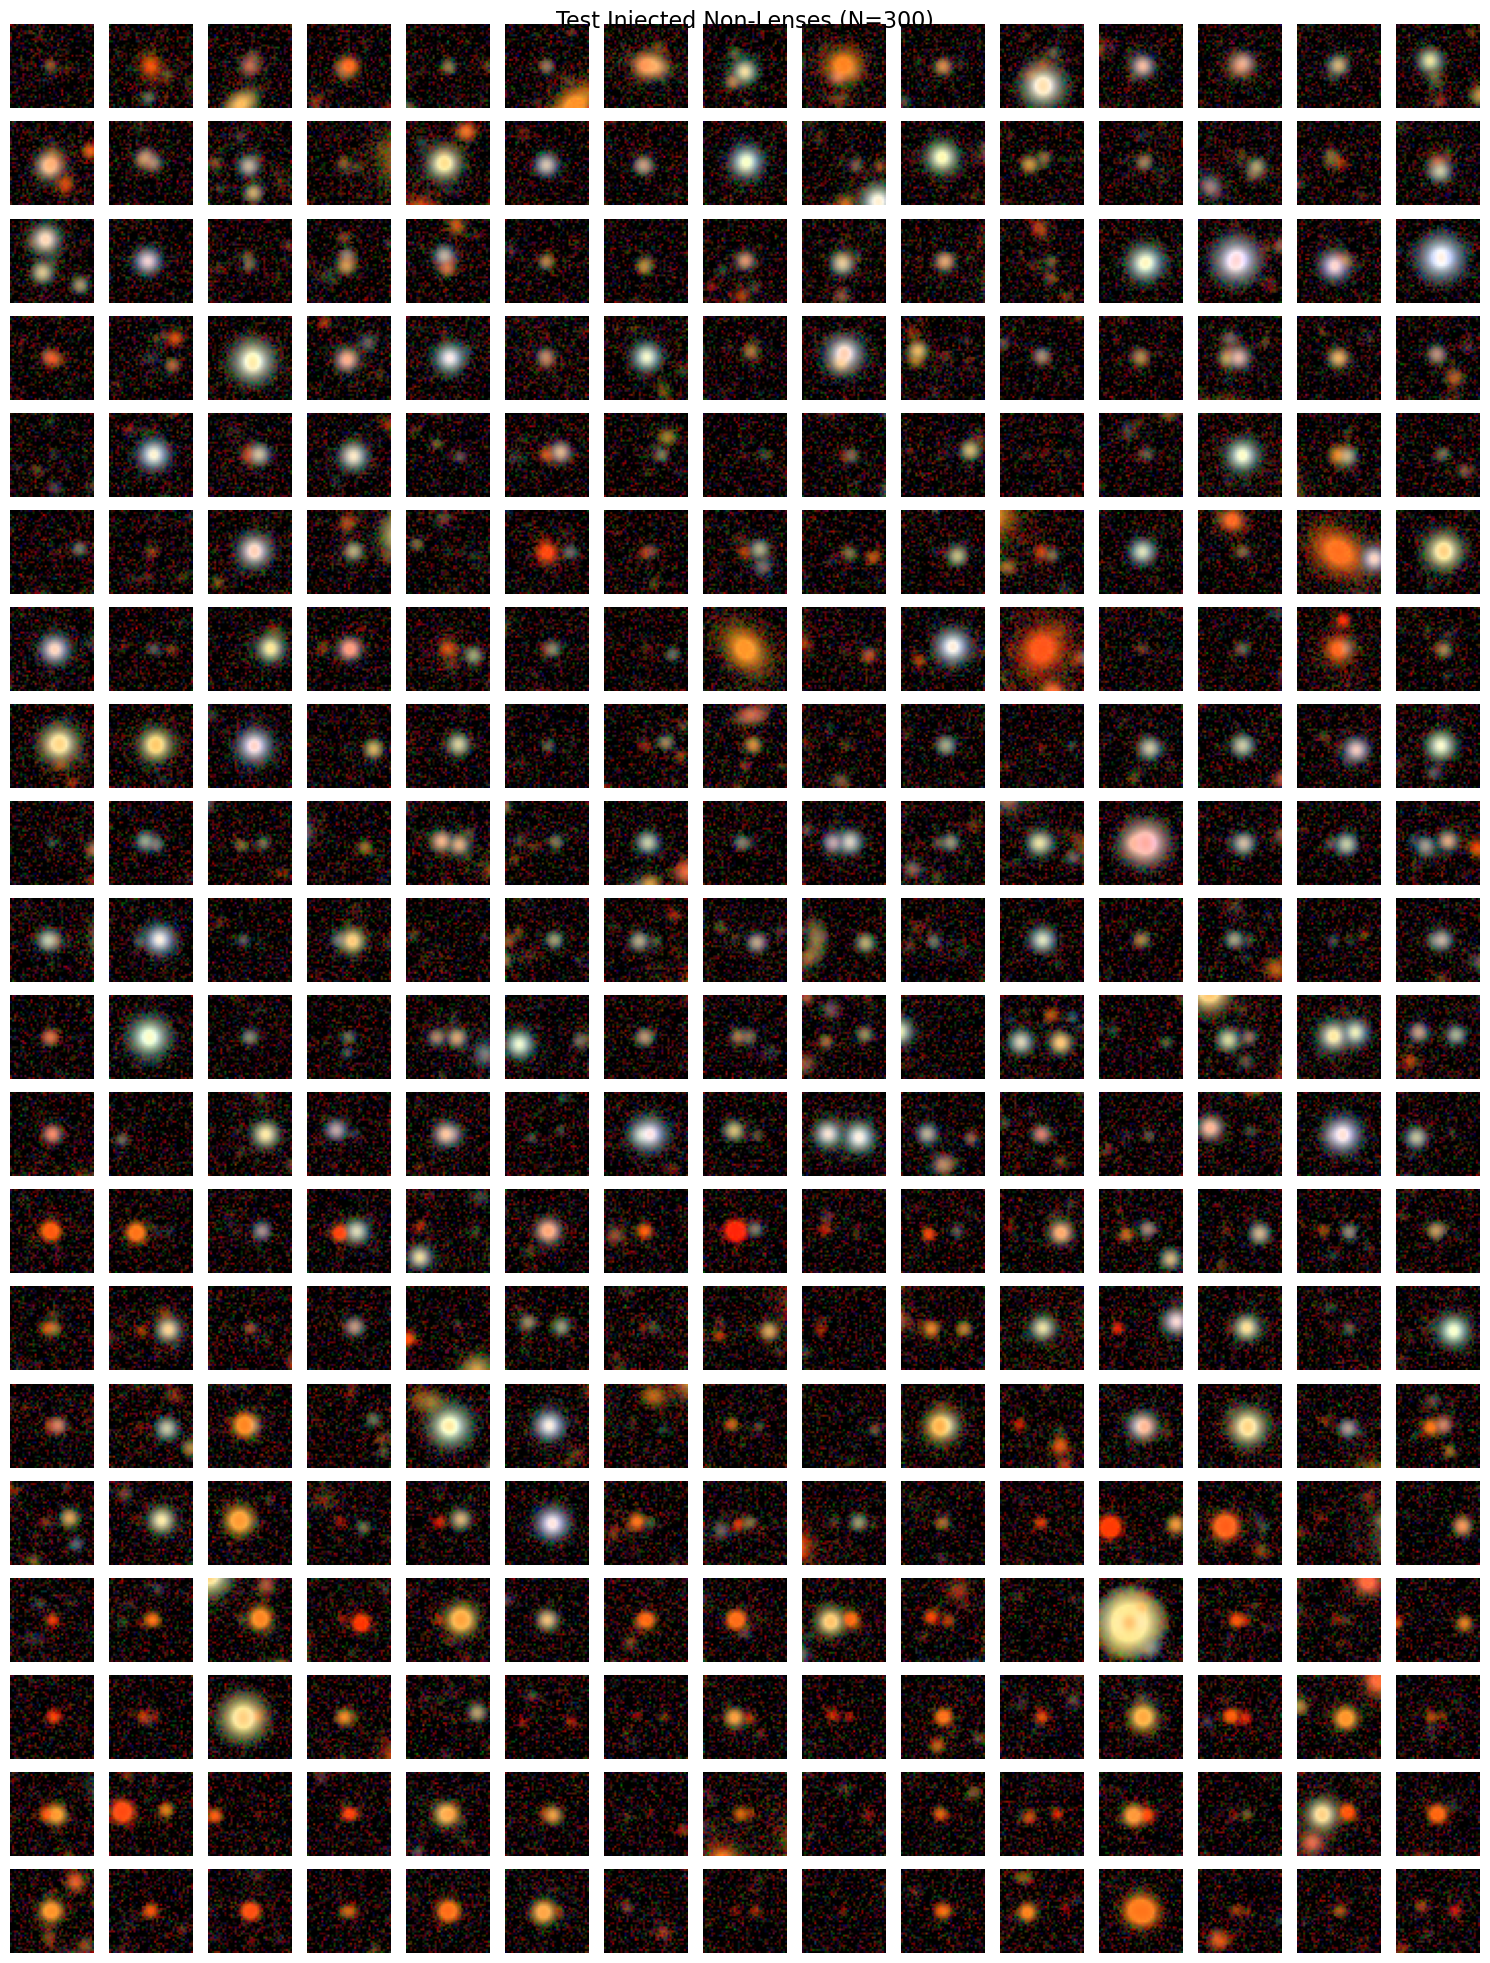

In [6]:
# ==========================================
# Cell 6: Montage - Visualize Injected Non-Lenses
# ==========================================
test_ids = [table_test[i]["Object ID"] for i in sorted(successful_indices)]

plot_injected_montage(
    test_ids,
    img_dir,
    band_list=band_list,
    rgb_bands=['i', 'r', 'g'],
    num_cols=15,
    plot_title=f"Test Injected Non-Lenses (N={len(test_ids)})",
)
plt.show()


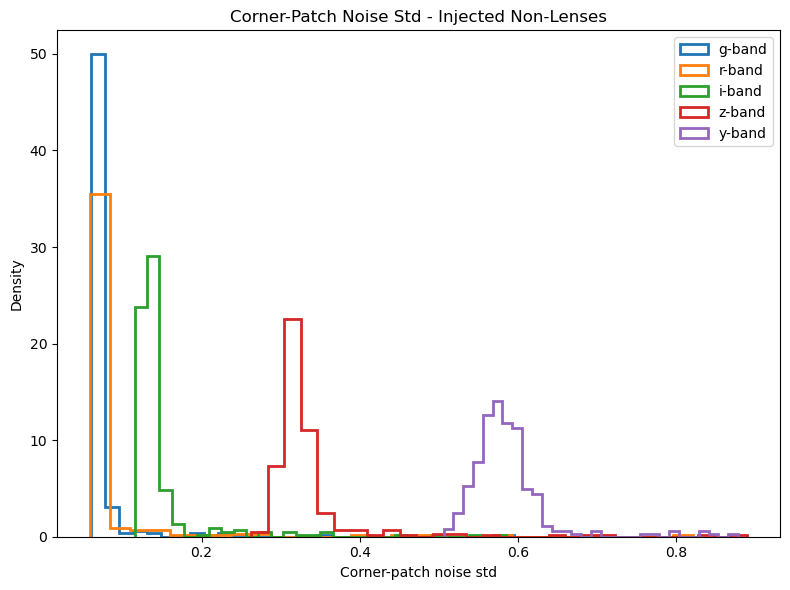

In [7]:
# ==========================================
# Cell 7: Noise Check - Corner-Patch Noise Std per Band
# ==========================================
plot_noise_std_histograms(
    test_ids,
    img_dir,
    band_list=band_list,
    corner_size=9,
    plot_title="Corner-Patch Noise Std - Injected Non-Lenses",
)
plt.show()


## Fixing Errors

In [8]:
import traceback
import numpy as np
from slsim.ImageSimulation.image_simulation import lens_image

# Grab the first non-lens that failed
test_obj_index = 0
test_lens = non_lenses_test[test_obj_index]

print(f"Testing False Positive Object Index: {test_obj_index}")

try:
    # Create a simple dummy PSF kernel (a normalized 5x5 array)
    dummy_psf = np.ones((5, 5)) / 25.0
    
    # Mimic the exact call used inside lsst_science_pipeline.add_object
    img = lens_image(
        lens_class=test_lens,
        band='g',
        mag_zero_point=27.0,
        num_pix=41,
        psf_kernel=dummy_psf,  # <-- Added the required PSF here
        transform_pix2angle=np.array([[0.2, 0], [0, 0.2]]),
        exposure_time=30
    )
    print("Success! Image generated without crashing.")
    
except Exception as e:
    print(f"\n--- FAILED with {type(e).__name__} ---")
    print(f"Error Message: {e}\n")
    print("--- Full Traceback ---")
    traceback.print_exc()

Testing False Positive Object Index: 0
Success! Image generated without crashing.


In [9]:
import traceback
import numpy as np
import matplotlib.pyplot as plt
from slsim.ImageSimulation.image_simulation import simulate_image, lens_image

# 1. Grab the first non-lens that is causing issues
test_obj_index = 0
test_lens = non_lenses_test[test_obj_index]

print(f"--- Testing False Positive Object Index: {test_obj_index} ---\n")

# Dummy parameters to mimic the DP0 environment
num_pix = 41
dummy_psf = np.ones((5, 5)) / 25.0
transform_matrix = np.array([[0.2, 0], [0, 0.2]])

# ==========================================
# TEST A: simulate_image (The High-Level Wrapper)
# ==========================================
print("TEST A: Running `simulate_image`...")
try:
    img_sim = simulate_image(
        lens_class=test_lens,
        band='g',
        num_pix=num_pix,
        add_noise=False,
        observatory="LSST",
        kwargs_psf={'psf_type': 'PIXEL', 'kernel_point_source': dummy_psf}
    )
    print("✅ `simulate_image` SUCCEEDED!")
except Exception as e:
    print("❌ `simulate_image` FAILED!")
    traceback.print_exc()

print("\n" + "="*40 + "\n")

# ==========================================
# TEST B: lens_image (The Low-Level Injector)
# ==========================================
print("TEST B: Running `lens_image`...")
try:
    img_lens = lens_image(
        lens_class=test_lens,
        band='g',
        mag_zero_point=27.0,
        num_pix=num_pix,
        psf_kernel=dummy_psf,
        transform_pix2angle=transform_matrix,
        exposure_time=30
    )
    print("✅ `lens_image` SUCCEEDED!")
except Exception as e:
    print(f"❌ `lens_image` FAILED with {type(e).__name__}: {e}")
    print("\n--- Full Traceback for lens_image ---")
    traceback.print_exc()

--- Testing False Positive Object Index: 0 ---

TEST A: Running `simulate_image`...
✅ `simulate_image` SUCCEEDED!


TEST B: Running `lens_image`...
✅ `lens_image` SUCCEEDED!
